Task 1: Dataset Loading and Dimensionality Inspection Load the Olivetti Faces dataset using sklearn.datasets.fetch_olivetti_faces. Print the total number of samples, unique target subjects, feature dimensions, and plot a 4 x 5 grid of sample faces labeled with their subject IDs.

Total number of samples: 400
Unique target subjects: 40
Feature dimensions: 4096 (64 x 64)


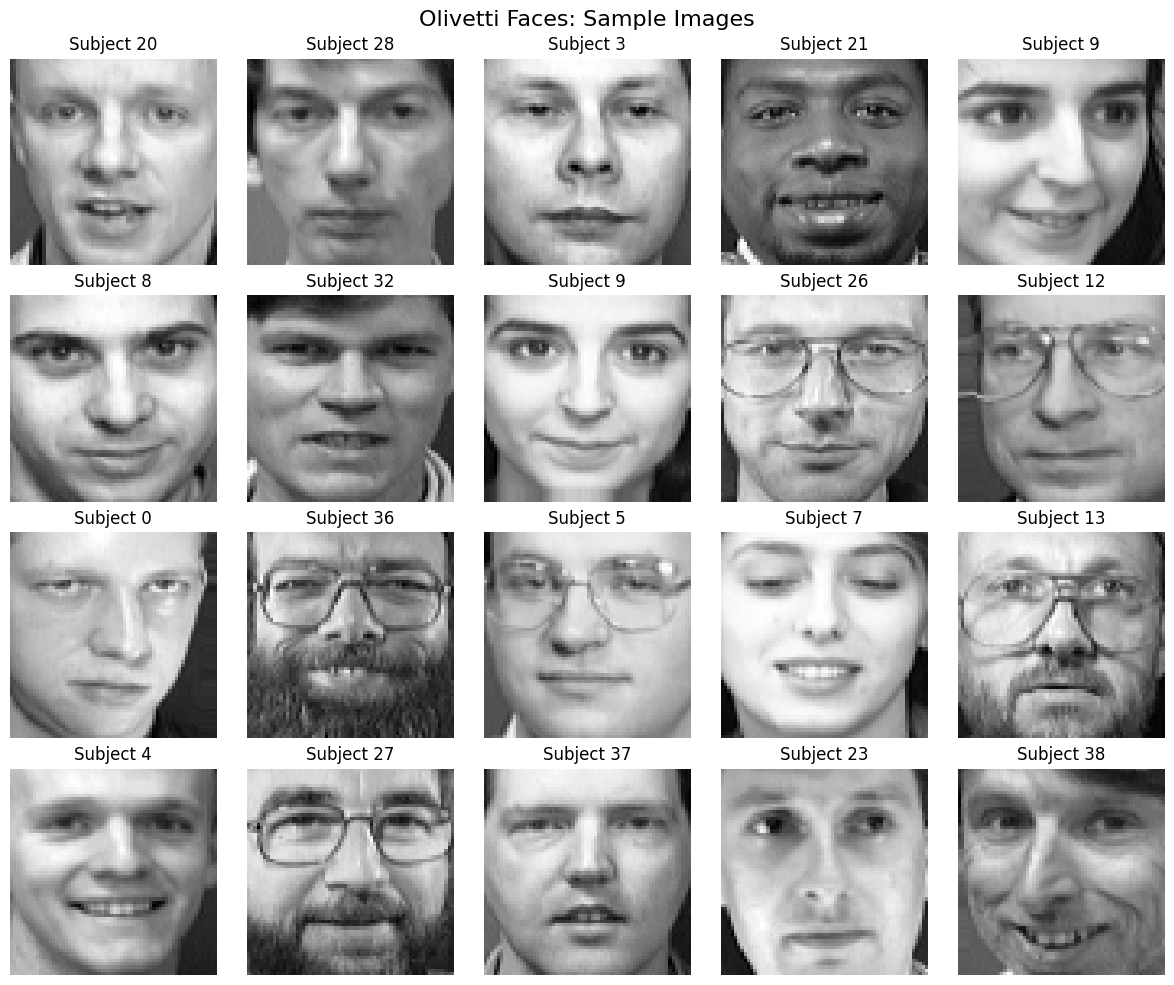

In [52]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces

df = fetch_olivetti_faces(shuffle=True, random_state=42)

# Seperate Data Frame
X = df.data        
y = df.target      
images = df.images 

# Print Data
print(f"Total number of samples: {X.shape[0]}")
print(f"Unique target subjects: {len(np.unique(y))}")
print(f"Feature dimensions: {X.shape[1]} ({images.shape[1]} x {images.shape[2]})")


# Sample Faces Grid
fig, axes = plt.subplots(4, 5, figsize=(12, 10))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(images[i], cmap="gray")
    ax.set_title(f"Subject {y[i]}")
    ax.axis("off")

plt.suptitle("Olivetti Faces: Sample Images", fontsize=16)
plt.tight_layout()
plt.show()

Task 2: Cumulative Explained Variance & Elbow Plot
Fit a full PCA model on the dataset. Plot both the individual explained variance ratio and the cumulative explained variance curve versus the number of principal components. Determine and print the exact number of components required to preserve 90%, 95%, and 99% of the cumulative variance.


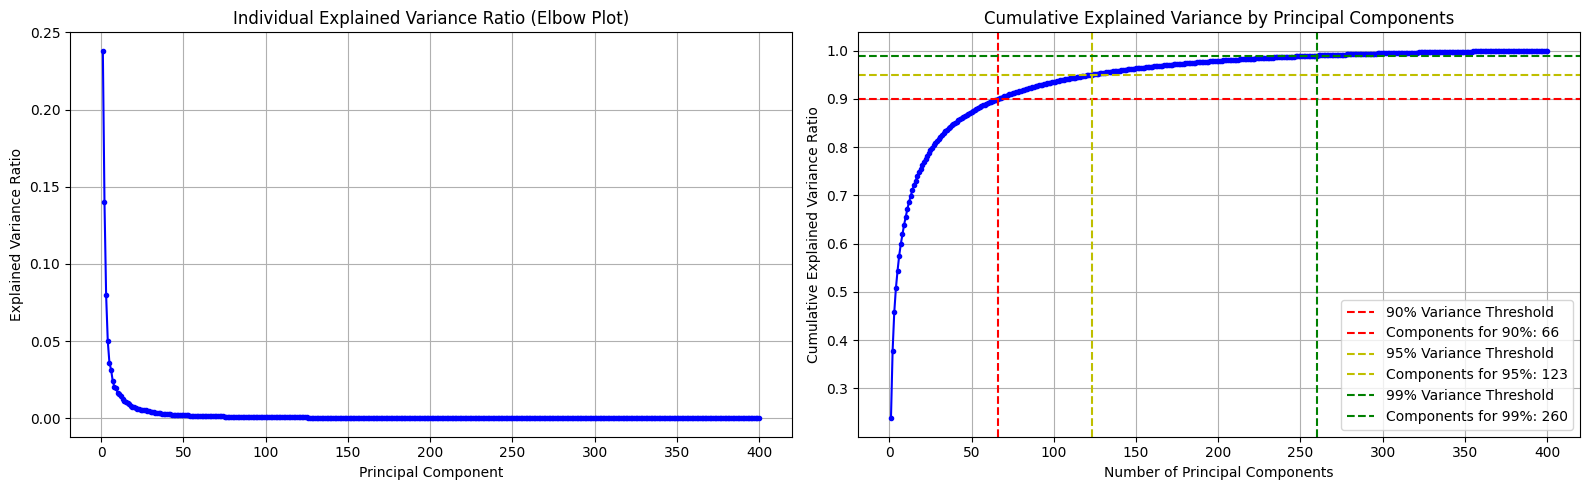

Components for 90% variance: 66
Components for 95% variance: 123
Components for 99% variance: 260


In [53]:
from sklearn.decomposition import PCA

# Fit PCA
pca = PCA(n_components=None)
pca.fit(X)

# Explained variance ratio for each component
explained_variance_ratio = pca.explained_variance_ratio_

# Cumulative explained variance
cumulative_variance_ratio = np.cumsum(explained_variance_ratio)
components = np.arange(1, len(explained_variance_ratio) + 1)

# Determine number of components needed for 90% 95% 99% variance
n_components_90 = np.argmax(cumulative_variance_ratio >= 0.90) + 1
n_components_95 = np.argmax(cumulative_variance_ratio >= 0.95) + 1
n_components_99 = np.argmax(cumulative_variance_ratio >= 0.99) + 1

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Individual explained variance 
axes[0].plot(components, explained_variance_ratio, marker='.', linestyle='-', color='b', linewidth=1.5)
axes[0].set_title('Individual Explained Variance Ratio (Elbow Plot)')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance Ratio')
axes[0].grid(True)

# Cumlative explained variance 
axes[1].plot(components, cumulative_variance_ratio, marker='.', linestyle='-', color='b', linewidth=1.5)

# 90
axes[1].axhline(y=0.90, color='r', linestyle='--', label='90% Variance Threshold')
axes[1].axvline(x=n_components_90, color='r', linestyle='--', label=f'Components for 90%: {n_components_90}')
# 95
axes[1].axhline(y=0.95, color='y', linestyle='--', label='95% Variance Threshold')
axes[1].axvline(x=n_components_95, color='y', linestyle='--', label=f'Components for 95%: {n_components_95}')
# 99
axes[1].axhline(y=0.99, color='g', linestyle='--', label='99% Variance Threshold')
axes[1].axvline(x=n_components_99, color='g', linestyle='--', label=f'Components for 99%: {n_components_99}')

axes[1].set_title('Cumulative Explained Variance by Principal Components')
axes[1].set_xlabel('Number of Principal Components')
axes[1].set_ylabel('Cumulative Explained Variance Ratio')
axes[1].legend(loc='lower right')
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Print the exact counts
print(f"Components for 90% variance: {n_components_90}")
print(f"Components for 95% variance: {n_components_95}")
print(f"Components for 99% variance: {n_components_99}")

Task 3: Image Compression and Reconstruction Analysis 
Select 5 representative facial images. Compress and reconstruct them using PCA with varying numbers of components; e.g., k in {10, 50, 100, 200, 300}. Plot a grid comparing the original images against their reconstructions across each component threshold, and compute/plot the Mean Squared Error (MSE) between original and reconstructed faces as a function of k.

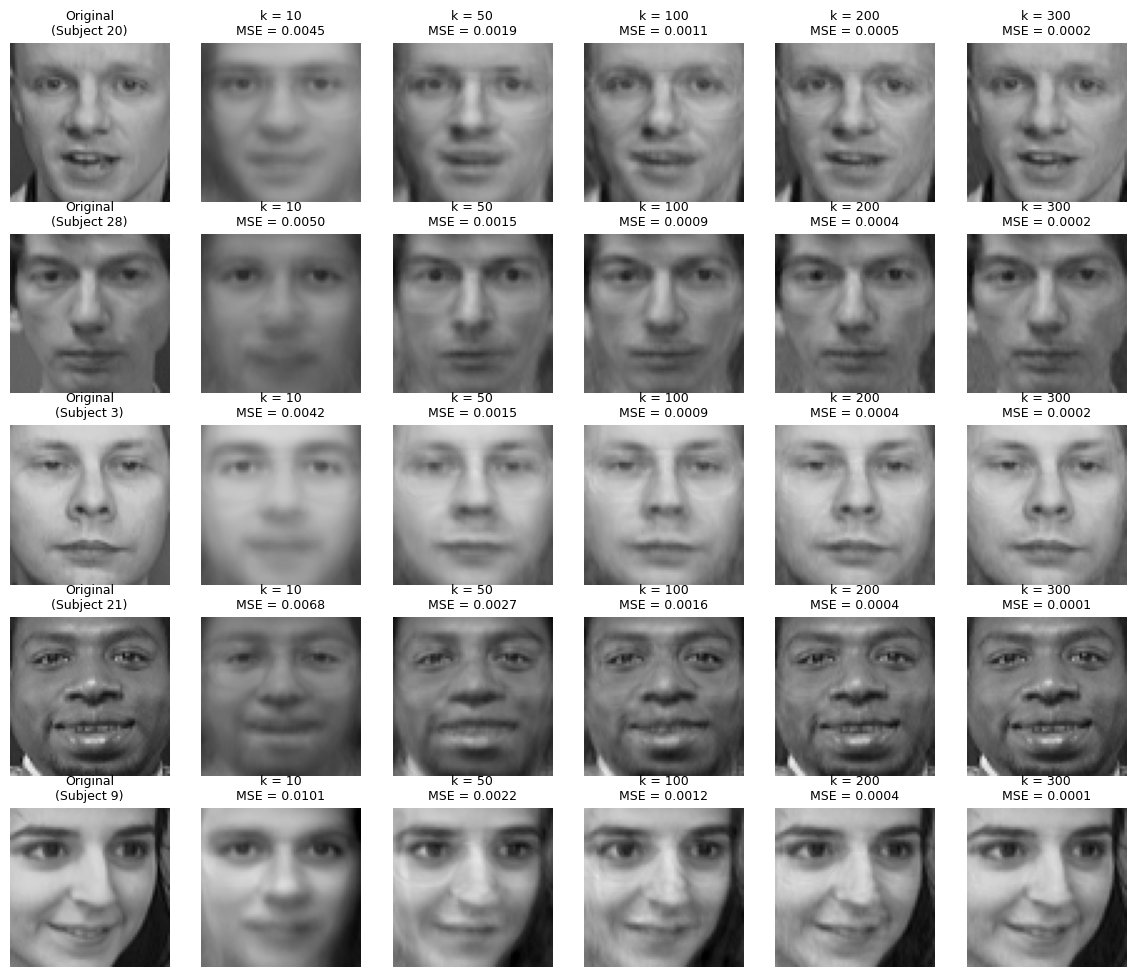

In [54]:
from sklearn.metrics import mean_squared_error

# Select 5 representative (Hard coded from Task 1)
subjects = [20, 28, 3, 21, 9] 
sample_idx = [np.where(y == s)[0][0] for s in subjects]
X_samples = X[sample_idx]
img_samples = images[sample_idx]

k_val = [10, 50, 100, 200, 300]

# Reconstruct 
reconstructions = {}   
mse_per_face = {}      

for k in k_val:
    pca_k = PCA(n_components=k, random_state=42)
    pca_k.fit(X)
    X_compressed = pca_k.transform(X_samples)             
    X_reconstructed = pca_k.inverse_transform(X_compressed) 
    reconstructions[k] = X_reconstructed
    mse_per_face[k] = np.array([
        mean_squared_error(X_samples[i], X_reconstructed[i]) for i in range(len(X_samples))
    ])

# Plot a grid comparing the original images against their reconstructions across each component threshold
p_rows = len(sample_idx)
p_cols = len(k_val) + 1
fig, axes = plt.subplots(p_rows, p_cols, figsize=(2.4 * p_cols, 2.4 * p_rows))

for r in range(p_rows):
    axes[r, 0].imshow(img_samples[r], cmap="gray", vmin=0, vmax=1)
    axes[r, 0].set_title(f"Original\n(Subject {y[sample_idx[r]]})", fontsize=9)
    axes[r, 0].axis("off")
    for c, k in enumerate(k_val, start=1):
        axes[r, c].imshow(reconstructions[k][r].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
        axes[r, c].set_title(f"k = {k}\nMSE = {mse_per_face[k][r]:.4f}", fontsize=9)
        axes[r, c].axis("off")

<Figure size 640x480 with 0 Axes>

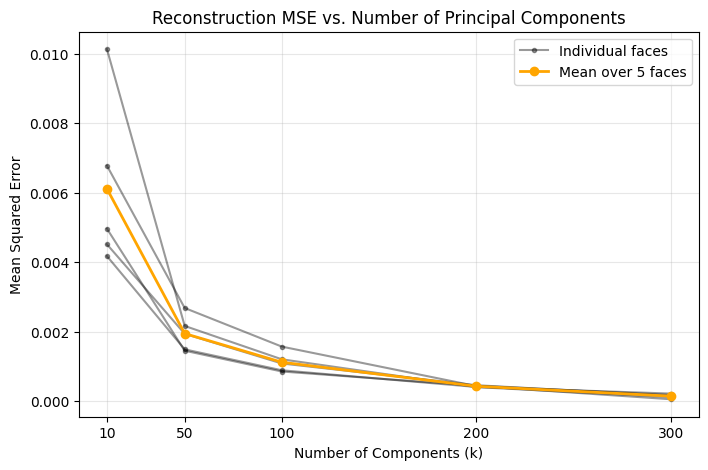

Mean MSE across the 5 faces:
  k =  10: 0.006115
  k =  50: 0.001948
  k = 100: 0.001122
  k = 200: 0.000432
  k = 300: 0.000147


In [55]:

# compute the MSE between original and reconstructed faces as a function of k.
plt.suptitle("PCA Reconstruction: Original vs. Different Numbers of Components", fontsize=15)
plt.tight_layout()
plt.show()

# Calculate MSE per K
mean_mse = [mse_per_face[k].mean() for k in k_val]

# Plot 
plt.figure(figsize=(8, 5))
for i in range(p_rows):
    plt.plot(k_val, [mse_per_face[k][i] for k in k_val],
             color="black", alpha=0.4, marker=".", label="Individual faces" if i == 0 else None)
plt.plot(k_val, mean_mse, marker="o", color="orange", linewidth=2, label="Mean over 5 faces")
plt.title("Reconstruction MSE vs. Number of Principal Components")
plt.xlabel("Number of Components (k)")
plt.ylabel("Mean Squared Error")
plt.xticks(k_val)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Print MSE Values 
print("Mean MSE across the 5 faces:")
for k, m in zip(k_val, mean_mse):
    print(f"  k = {k:>3}: {m:.6f}")

Task 4: Visualization of "Eigenfaces" 
Extract the principal components (eigenvectors) from your fitted PCA model. Reshape the first 15 principal components back into 64 x 64 grids and visualize them in a 3 x 5  plot grid ("Eigenfaces"). Annotate each plot with the percentage of total variance explained by that specific component.

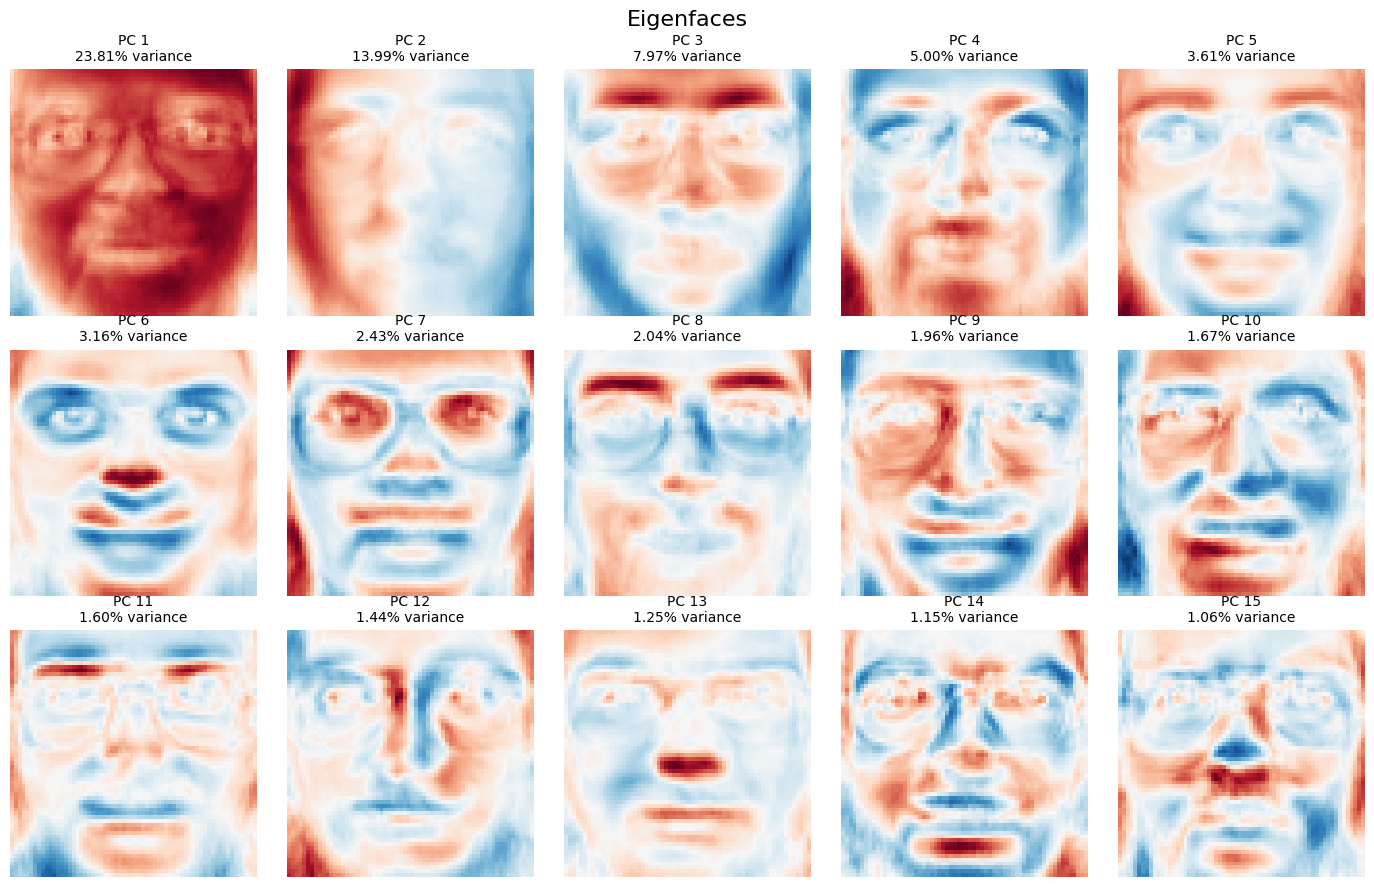

Variance explained by the first 15 Eigenfaces: 72.12%


In [56]:
# Eigenvectors from fitted PCA
eigenfaces = pca.components_                     
variance_pct = pca.explained_variance_ratio_ * 100

n_show = 15
fig, axes = plt.subplots(3, 5, figsize=(14, 9))

for i, ax in enumerate(axes.ravel()):
    eigenface = eigenfaces[i].reshape(64, 64)
    lim = np.abs(eigenface).max()                
    ax.imshow(eigenface, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_title(f"PC {i + 1}\n{variance_pct[i]:.2f}% variance", fontsize=10)
    ax.axis("off")

plt.suptitle("Eigenfaces", fontsize=16)
plt.tight_layout()
plt.show()

# Total variance
print(f"Variance explained by the first 15 Eigenfaces: {variance_pct[:n_show].sum():.2f}%")

Task 5: Classification Baseline — Raw vs. PCA-Reduced Features (Linear Model) 

Perform a stratified train/test split (80/20). Train a LogisticRegression classifier on:

    1. The raw 4,096-dimensional feature vectors.

    2. The PCA-reduced feature vectors using the 95% variance threshold fitted strictly on the training set

Evaluate and print the test accuracy and training time for both, and visualize the performance comparison in a dual-axis bar plot (Accuracy vs. Training Time).

In [57]:
import time
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# Log Regression RAW
log_raw = LogisticRegression(max_iter=1000, random_state=42)
start = time.perf_counter()
log_raw.fit(X_train, y_train)
time_raw = time.perf_counter() - start
acc_raw = accuracy_score(y_test, log_raw.predict(X_test))

# PCA reduced feature vectors 
pca_reduced = PCA(n_components=0.95, random_state=42)
X_train_pca = pca_reduced.fit_transform(X_train)   
X_test_pca = pca_reduced.transform(X_test)         

log_pca = LogisticRegression(max_iter=1000, random_state=42)
start = time.perf_counter()
log_pca.fit(X_train_pca, y_train)
time_pca = time.perf_counter() - start
acc_pca = accuracy_score(y_test, log_pca.predict(X_test_pca))

# Results
print("\nResults:")
print(f"  Raw:          accuracy = {acc_raw:.4f}, training time = {time_raw:.3f} s")
print(f"  PCA Reduced:  accuracy = {acc_pca:.4f}, training time = {time_pca:.3f} s")


Results:
  Raw:          accuracy = 0.9750, training time = 14.323 s
  PCA Reduced:  accuracy = 0.9750, training time = 0.348 s


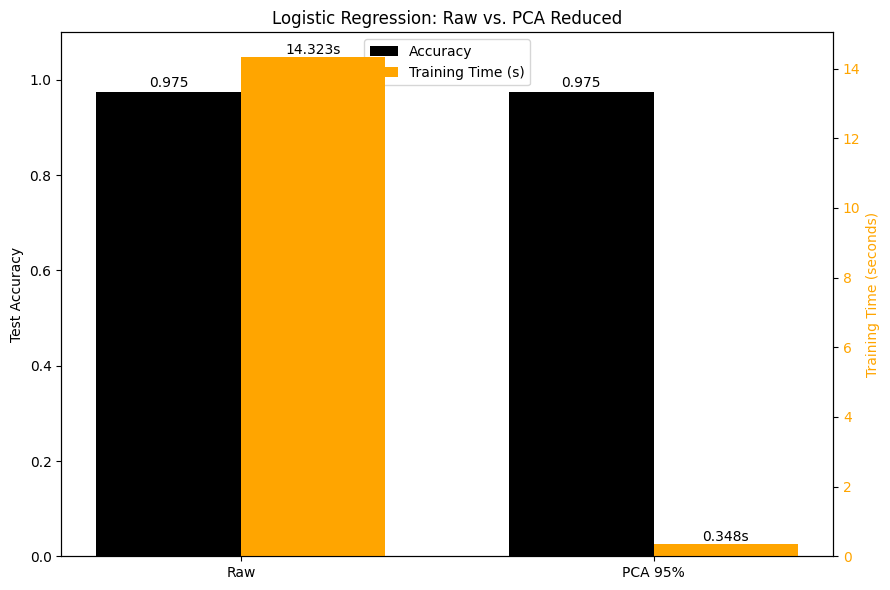

In [58]:
# Plot dual-axis bar plot (Accuracy vs. Training Time)
labels = ["Raw", "PCA 95%"]
accuracies = [acc_raw, acc_pca]
times = [time_raw, time_pca]

x = np.arange(len(labels))
width = 0.35

fig, ax1 = plt.subplots(figsize=(9, 6))
bars1 = ax1.bar(x - width/2, accuracies, width, color="black", label="Accuracy")
ax1.set_ylabel("Test Accuracy", color="black")
ax1.set_ylim(0, 1.1)
ax1.tick_params(axis="y", labelcolor="black")

ax2 = ax1.twinx()
bars2 = ax2.bar(x + width/2, times, width, color="orange", label="Training Time (s)")
ax2.set_ylabel("Training Time (seconds)", color="orange")
ax2.tick_params(axis="y", labelcolor="orange")

ax1.set_xticks(x)
ax1.set_xticklabels(labels)
ax1.set_title("Logistic Regression: Raw vs. PCA Reduced")

# Value labels on top of the bars
for b in bars1:
    ax1.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01, f"{b.get_height():.3f}", ha="center")
for b in bars2:
    ax2.text(b.get_x() + b.get_width()/2, b.get_height(), f"{b.get_height():.3f}s", ha="center", va="bottom")

# Combined legend
handles = [bars1, bars2]
ax1.legend(handles, ["Accuracy", "Training Time (s)"], loc="upper center")

plt.tight_layout()
plt.show()

Task 6: Non-Linear Classification (Kernel SVM) 

Train a SVC with an RBF kernel on the PCA-reduced features (95% variance). Record its training time and test accuracy, and plot a confusion matrix or classification summary comparing its predictions against the linear baseline.

In [59]:
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# SVM PCA reduced
svm_reduced = SVC(kernel="rbf", random_state=42)

# Train 
start = time.perf_counter()
svm_reduced.fit(X_train_pca, y_train)
time_svm = time.perf_counter() - start

y_pred_svm = svm_reduced.predict(X_test_pca)
acc_svm = accuracy_score(y_test, y_pred_svm)

# Print Results 
print(f"Logistic Regression: accuracy = {acc_pca:.4f}, training time = {time_pca:.3f} s")
print(f"SVC RBF:             accuracy = {acc_svm:.4f}, training time = {time_svm:.3f} s")



Logistic Regression: accuracy = 0.9750, training time = 0.348 s
SVC RBF:             accuracy = 0.9500, training time = 0.031 s


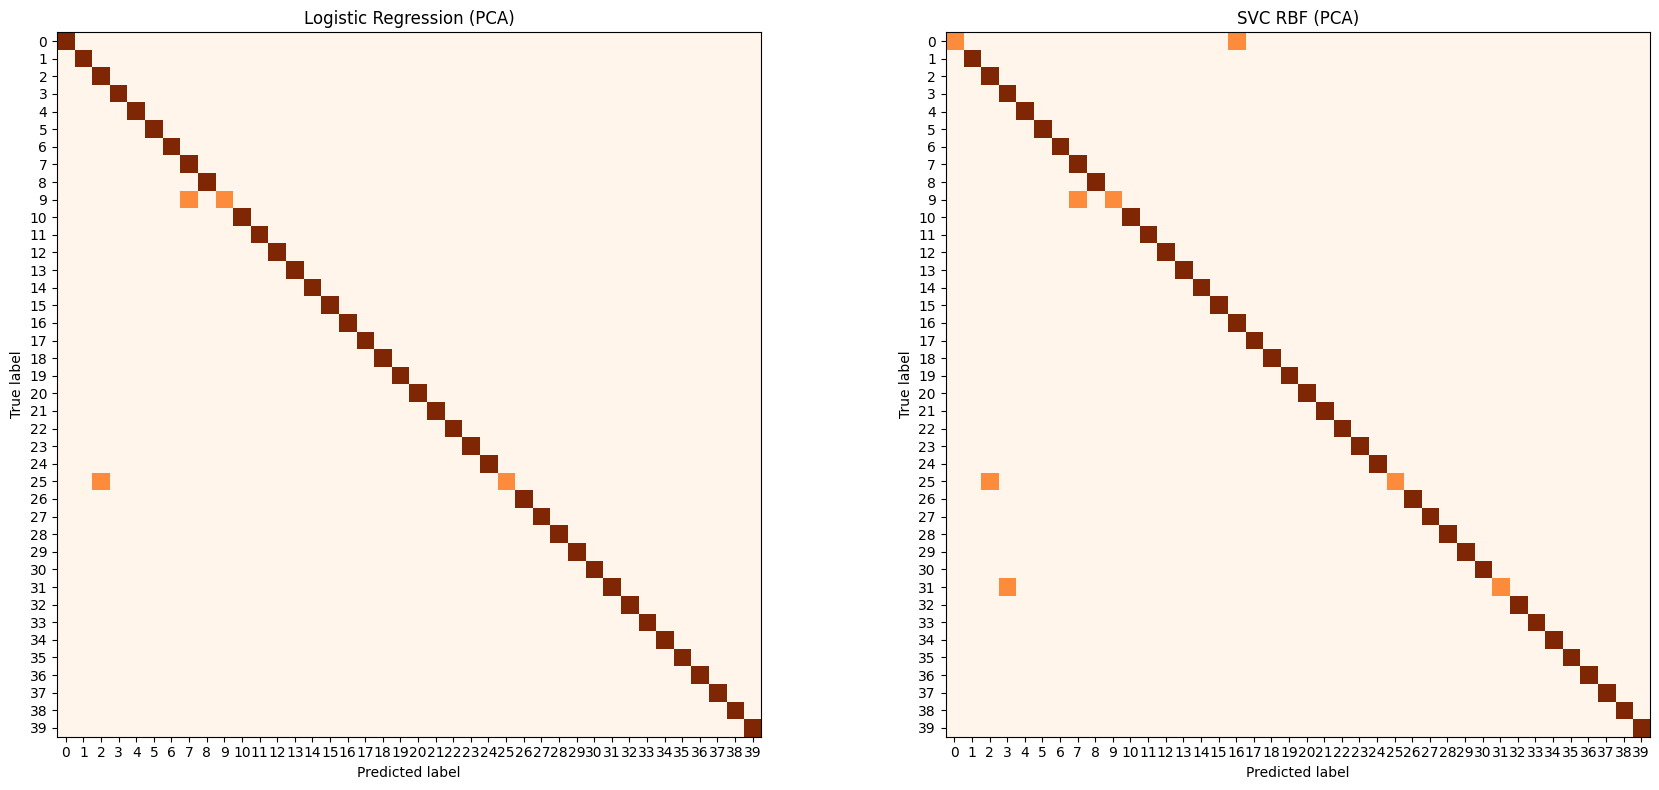

In [60]:
# Plot a Confusion Matrix

y_pred_lr = log_pca.predict(X_test_pca)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, preds, title in zip(axes, [y_pred_lr, y_pred_svm],
                            ["Logistic Regression (PCA)", "SVC RBF (PCA)"]):
    cm = confusion_matrix(y_test, preds, labels=np.arange(40))
    ConfusionMatrixDisplay(cm).plot(ax=ax, cmap="Oranges", colorbar=False, include_values=False)
    ax.set_title(title)
plt.tight_layout()
plt.show()


Task 7: Ensemble Classification on PCA Features 
Construct a VotingClassifier (soft voting) combining a Polynomial Kernel SVM (degree=2), an RBF Kernel SVM, and a RandomForestClassifier (n_estimators=100). Train the ensemble on the PCA-reduced features, record training time and accuracy, and compare its performance against the single linear and non-linear models.

Logistic Regression: accuracy = 0.9750, training time = 0.348 s
SVC RBF:             accuracy = 0.9500, training time = 0.031 s
Soft Voting:         accuracy = 0.9750, training time = 0.604 s


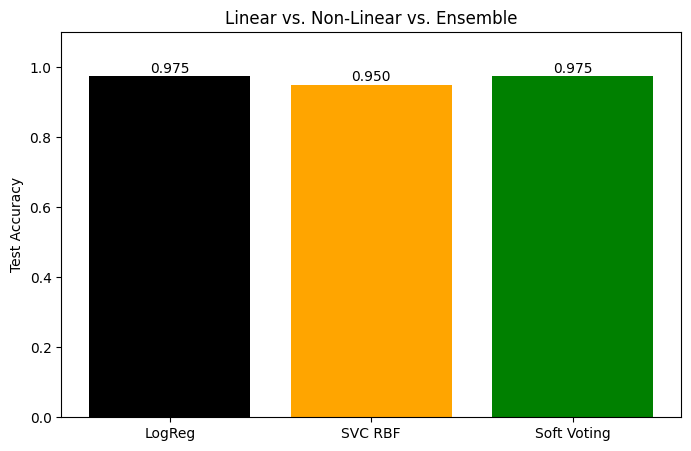

In [61]:
from sklearn.ensemble import VotingClassifier, RandomForestClassifier

base_models = [
    ("svc_poly", SVC(kernel="poly", degree=2, probability=True, random_state=42)),
    ("svc_rbf",  SVC(kernel="rbf", probability=True, random_state=42)),
    ("rf",       RandomForestClassifier(n_estimators=100, random_state=42)),
]

# Soft Voting
soft_vote = VotingClassifier(estimators=base_models, voting="soft")

# Train
start = time.perf_counter()
soft_vote.fit(X_train_pca, y_train)
time_soft = time.perf_counter() - start

# Evaluate
y_pred_soft = soft_vote.predict(X_test_pca)
acc_soft = accuracy_score(y_test, y_pred_soft)

# Compare performance against single linear and non-linear models
print(f"Logistic Regression: accuracy = {acc_pca:.4f}, training time = {time_pca:.3f} s")
print(f"SVC RBF:             accuracy = {acc_svm:.4f}, training time = {time_svm:.3f} s")
print(f"Soft Voting:         accuracy = {acc_soft:.4f}, training time = {time_soft:.3f} s")

# Compare using Bar Chart 
labels = ["LogReg", "SVC RBF", "Soft Voting"]
accs = [acc_pca, acc_svm, acc_soft]

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, accs, color=["black", "orange", "green"])
for b in bars:
    plt.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01, f"{b.get_height():.3f}", ha="center")
plt.ylim(0, 1.1)
plt.ylabel("Test Accuracy")
plt.title("Linear vs. Non-Linear vs. Ensemble")
plt.show()


Task 8: Comprehensive Comparative Evaluation 
Create a single summary bar plot comparing Accuracy (primary y-axis) and Training Time in seconds (secondary y-axis) across all four model configurations:
    1. Logistic Regression (Raw Features)
    2. Logistic Regression (PCA-Reduced)
    3. Support Vector Classifier with RBF Kernel (PCA-Reduced)
    4. Soft Voting Ensemble (PCA-Reduced)

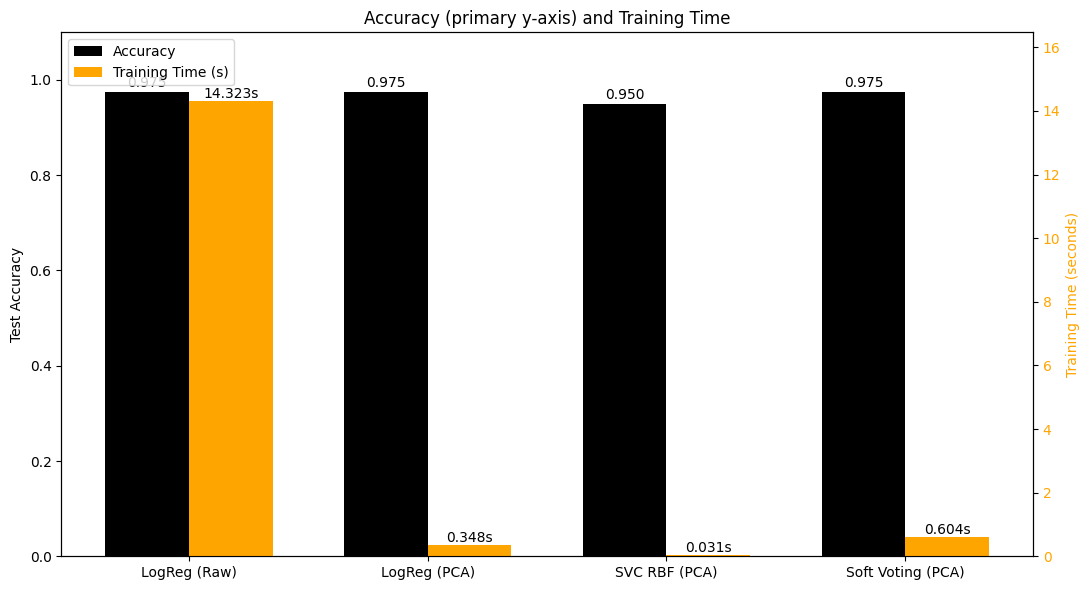

In [62]:
# Bar Plot Accuracy vs. Training Time all models
labels = ["LogReg (Raw)",
          "LogReg (PCA)",
          "SVC RBF (PCA)",
          "Soft Voting (PCA)"]

accuracies = [acc_raw, acc_pca, acc_svm, acc_soft]
times = [time_raw, time_pca, time_svm, time_soft]

x = np.arange(len(labels))
width = 0.35

fig, ax1 = plt.subplots(figsize=(11, 6))
bars1 = ax1.bar(x - width/2, accuracies, width, color="black", label="Accuracy")
ax1.set_ylabel("Test Accuracy", color="black")
ax1.set_ylim(0, 1.1)
ax1.tick_params(axis="y", labelcolor="black")

ax2 = ax1.twinx()
bars2 = ax2.bar(x + width/2, times, width, color="orange", label="Training Time (s)")
ax2.set_ylabel("Training Time (seconds)", color="orange")
ax2.tick_params(axis="y", labelcolor="orange")
ax2.set_ylim(0, max(times) * 1.15)

ax1.set_xticks(x)
ax1.set_xticklabels(labels)
ax1.set_title("Accuracy (primary y-axis) and Training Time")

# Value labels on top of the bars
for b in bars1:
    ax1.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01, f"{b.get_height():.3f}", ha="center")
for b in bars2:
    ax2.text(b.get_x() + b.get_width()/2, b.get_height(), f"{b.get_height():.3f}s", ha="center", va="bottom")

# Combined legend
ax1.legend([bars1, bars2], ["Accuracy", "Training Time (s)"], loc="upper left")

plt.tight_layout()
plt.show()